# Canary Selection

## Setup

In [1]:
import itertools
import matplotlib.pyplot as plt
import polars as pl
import polars.selectors as cs

from datetime import date
from matplotlib.ticker import MultipleLocator, EngFormatter
from privacy_and_grokking.artifacts.local import get_plots_dir
from shared import setup, SETUPS, BATCHES, preprocess_info_rmia, preprocess_metrics_df

In [2]:
setup()

In [ ]:
metrics_df_v1 = pl.read_parquet("../../cache/canary-selection-v1_mlflow_export.parquet")
metrics_df_v1 = preprocess_metrics_df(metrics_df_v1)

metrics_df_v2 = pl.read_parquet("../../cache/canary-selection-v2_mlflow_export.parquet")
metrics_df_v2 = preprocess_metrics_df(metrics_df_v2)

metrics_df = pl.concat([metrics_df_v1, metrics_df_v2], how="diagonal")

In [5]:
info_rmia_df_v1 = pl.read_parquet("../../cache/canary-selection-v1/informia_results.parquet")
info_rmia_df_v1 = preprocess_info_rmia(info_rmia_df_v1)

info_rmia_df_v2 = pl.read_parquet("../../cache/canary-selection-v2/informia_results.parquet")
info_rmia_df_v2 = preprocess_info_rmia(info_rmia_df_v2)

info_rmia_df = pl.concat([info_rmia_df_v1, info_rmia_df_v2], how="diagonal")

## Overview

In [6]:
info_rmia_df.head()

auc,tpr_at_0_fpr,tpr_at_0.01_fpr,tpr_at_0.05_fpr,tpr_at_0.1_fpr,step,optimal_a,optimal_a_auc,canary,run_name,id,target_run_id,val_run_id,ref_run_ids,run_ids,title
f64,f64,f64,f64,f64,i64,f64,f64,bool,str,str,str,str,list[str],list[str],str
0.487138,0.006,0.012,0.056,0.11,0,0.0,0.490878,false,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(IX) MADD (CE) Grokking"""
0.4184,0.0,0.0,0.0,0.0,0,1.0,0.5168,true,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(IX) MADD (CE) Grokking"""
0.213942,0.0,0.004,0.006,0.01,10000,1.0,0.716002,false,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(IX) MADD (CE) Grokking"""
0.7272,0.12,0.12,0.12,0.12,10000,0.0,0.6688,true,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(IX) MADD (CE) Grokking"""
0.439506,0.006,0.014,0.054,0.102,20000,0.0,0.488254,false,"""SQUARE_WATERMARK_GROK_MADD_CE_…","""SQUARE_WATERMARK_GROK_MADD_CE_…","""0b0d8d8d9366438ea7a2a42d82e7c6…","""522baa47cee54ed68a897e57cff7c3…","[""5c15c1a245624eb0bf3599cec1a4575b"", ""349db74785f64fa2918422546c2c7516"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","[""0b0d8d8d9366438ea7a2a42d82e7c693"", ""522baa47cee54ed68a897e57cff7c329"", … ""64f05a1a955c492f934452e0e3ca5a7a""]","""(IX) MADD (CE) Grokking"""


In [7]:
info_rmia_df.describe()

statistic,auc,tpr_at_0_fpr,tpr_at_0.01_fpr,tpr_at_0.05_fpr,tpr_at_0.1_fpr,step,optimal_a,optimal_a_auc,canary,run_name,id,target_run_id,val_run_id,ref_run_ids,run_ids,title
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,f64,f64,str
"""count""",1376.0,1376.0,1376.0,1376.0,1376.0,1376.0,1376.0,1376.0,1376.0,"""1376""","""1376""","""1376""","""1376""",1376.0,1376.0,"""1328"""
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""",0.0,0.0,"""48"""
"""mean""",0.724353,0.215045,0.23206,0.308985,0.367953,71511.627907,0.360174,0.728999,0.5,null,null,null,null,null,null,null
"""std""",0.181789,0.364674,0.358292,0.349817,0.339404,46485.624867,0.384157,0.178102,null,null,null,null,null,null,null,null
"""min""",0.205932,0.0,0.0,0.0,0.0,0.0,0.0,0.3616,0.0,"""GAUSSIAN_NOISE_GROK_MADD_CE_TR…","""GAUSSIAN_NOISE_GROK_MADD_CE_TR…","""00531a793b25490b966d3514d5b87e…","""05ee86c99dda445ba1a7d3b4c42b53…",null,null,"""(I) MLP (MSE) Grokking"""
"""25%""",0.560128,0.0,0.016,0.072,0.124,30000.0,0.0,0.563178,null,null,null,null,null,null,null,null
"""50%""",0.6982,0.014,0.04,0.126,0.2,70000.0,0.2,0.694802,null,null,null,null,null,null,null,null
"""75%""",0.883664,0.162,0.216,0.4,0.52,110000.0,0.8,0.884,null,null,null,null,null,null,null,null
"""max""",1.0,1.0,1.0,1.0,1.0,150000.0,1.0,1.0,1.0,"""UNIFORM_NOISE_NO_GROK_MNIST_MS…","""UNIFORM_NOISE_NO_GROK_MNIST_MS…","""fd203770e43143deac1b450aac3d12…","""feae7ea5e19f4586b741513ee85c4d…",null,null,"""(VIII) ViT (CE) Baseline"""


In [8]:
metrics_df.head()

run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/nc/nc1,eval/nc/nc2_equinorm_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc4_test,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4,eval/nc/nc3,eval/nc/rnc1/train_impl,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/test_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test,eval/train/canary_accuracy,eval/train/accuracy,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/std,eval/train/loss/mse/mean,eval/test/canary_accuracy,eval/test/accuracy,eval/test/canary_loss/mse/mean,eval/test/canary_loss/mse/std,eval/test/canary_loss/cross_entropy/mean,…,eval/train/canary_loss/mse_prob/mean,eval/train/canary_loss/mse_prob/std,eval/train/loss/mse/top10_idx_3,eval/train/loss/mse/top10_idx_9,eval/train/loss/mse/top10_share,eval/train/loss/mse/top10_idx_4,eval/train/loss/mse/top10_idx_0,eval/train/loss/mse/top10_idx_7,eval/train/loss/mse/top10_idx_5,eval/train/loss/mse/top10_idx_8,eval/train/loss/mse/top10_idx_2,eval/train/loss/mse/top10_idx_6,eval/train/loss/mse/top10_idx_1,eval/train/loss/mse_prob/top10_idx_1,eval/train/loss/mse_prob/std,eval/train/loss/mse_prob/top10_idx_6,eval/train/loss/mse_prob/top10_idx_8,eval/train/loss/mse_prob/top10_idx_2,eval/train/loss/mse_prob/top10_idx_5,eval/train/loss/mse_prob/top10_idx_7,eval/train/loss/mse_prob/top10_idx_0,eval/train/loss/mse_prob/mean,eval/train/loss/mse_prob/top10_idx_4,eval/train/loss/mse_prob/top10_idx_3,eval/train/loss/mse_prob/top10_idx_9,eval/train/loss/mse_prob/top10_share,eval/train/loss/cross_entropy/top10_idx_4,eval/train/loss/cross_entropy/top10_share,eval/train/loss/cross_entropy/top10_idx_3,eval/train/loss/cross_entropy/top10_idx_9,eval/train/loss/cross_entropy/top10_idx_7,eval/train/loss/cross_entropy/top10_idx_0,eval/train/loss/cross_entropy/top10_idx_8,eval/train/loss/cross_entropy/top10_idx_2,eval/train/loss/cross_entropy/top10_idx_5,eval/train/loss/cross_entropy/top10_idx_1,eval/train/loss/cross_entropy/top10_idx_6
str,str,i64,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:47.098,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:12.020,0.0,-0.000305,2.020342,0.038248,0.242497,0.185493,0.9234,0.214121,0.058478,0.110666,0.931579,1.995042,0.350759,0.141888,0.350787,0.345635,0.126295,0.124347,0.1,0.077895,68.045837,60.762383,3974.813477,5751.144531,66.919189,50.410038,2755.906738,1816.020142,0.07,0.0782,2343.800537,2474.350098,73.447357,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:04:21.507,null,-0.000305,2.020342,0.038248,0.242497,0.185493,0.9234,0.214121,0.058478,0.110666,0.931579,1.995042,0.350759,0.141888,0.350787,0.345635,0.126295,0.124347,0.1,0.077895,68.045837,60.762383,3974.813477,5751.144531,66.919189,50.410038,2755.906738,1816.020142,0.07,

In [9]:
metrics_df.describe()

statistic,run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/nc/nc1,eval/nc/nc2_equinorm_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc4_test,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4,eval/nc/nc3,eval/nc/rnc1/train_impl,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/test_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test,eval/train/canary_accuracy,eval/train/accuracy,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/std,eval/train/loss/mse/mean,eval/test/canary_accuracy,eval/test/accuracy,eval/test/canary_loss/mse/mean,eval/test/canary_loss/mse/std,…,eval/train/canary_loss/mse_prob/mean,eval/train/canary_loss/mse_prob/std,eval/train/loss/mse/top10_idx_3,eval/train/loss/mse/top10_idx_9,eval/train/loss/mse/top10_share,eval/train/loss/mse/top10_idx_4,eval/train/loss/mse/top10_idx_0,eval/train/loss/mse/top10_idx_7,eval/train/loss/mse/top10_idx_5,eval/train/loss/mse/top10_idx_8,eval/train/loss/mse/top10_idx_2,eval/train/loss/mse/top10_idx_6,eval/train/loss/mse/top10_idx_1,eval/train/loss/mse_prob/top10_idx_1,eval/train/loss/mse_prob/std,eval/train/loss/mse_prob/top10_idx_6,eval/train/loss/mse_prob/top10_idx_8,eval/train/loss/mse_prob/top10_idx_2,eval/train/loss/mse_prob/top10_idx_5,eval/train/loss/mse_prob/top10_idx_7,eval/train/loss/mse_prob/top10_idx_0,eval/train/loss/mse_prob/mean,eval/train/loss/mse_prob/top10_idx_4,eval/train/loss/mse_prob/top10_idx_3,eval/train/loss/mse_prob/top10_idx_9,eval/train/loss/mse_prob/top10_share,eval/train/loss/cross_entropy/top10_idx_4,eval/train/loss/cross_entropy/top10_share,eval/train/loss/cross_entropy/top10_idx_3,eval/train/loss/cross_entropy/top10_idx_9,eval/train/loss/cross_entropy/top10_idx_7,eval/train/loss/cross_entropy/top10_idx_0,eval/train/loss/cross_entropy/top10_idx_8,eval/train/loss/cross_entropy/top10_idx_2,eval/train/loss/cross_entropy/top10_idx_5,eval/train/loss/cross_entropy/top10_idx_1,eval/train/loss/cross_entropy/top10_idx_6
str,str,str,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""159792""","""159792""",159792.0,"""159792""",60552.0,121392.0,102528.0,102288.0,102528.0,102528.0,102528.0,102528.0,102528.0,102528.0,102528.0,102288.0,102528.0,102528.0,102528.0,102528.0,102528.0,102528.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,121392.0,…,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0,24240.0
"""null_count""","""0""","""0""",0.0,"""0""",99240.0,38400.0,57264.0,57504.0,57264.0,57264.0,57264.0,57264.0,57264.0,57264.0,57264.0,57504.0,57264.0,57264.0,57264.0,57264.0,57264.0,57264.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,38400.0,…,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0,135552.0
"""mean""",null,null,53615.19976,"""2026-09-15 20:44:10.923000""",5633.521205,0.094999,19.714133,0.098661,0.192626,0.157325,0.152757,0.157219,0.097791,0.12638

In [10]:
metrics_df.columns

['run_id',
 'run_name',
 'step',
 'timestamp',
 'epoch',
 'eval/generalization_gap',
 'eval/nc/nc1',
 'eval/nc/nc2_equinorm_weights',
 'eval/nc/nc2_equiangularity',
 'eval/nc/nc2_maximal_angle_equiangularity',
 'eval/nc/nc4_test',
 'eval/nc/nc2_equinorm',
 'eval/nc/nc2_equiangularity_weights',
 'eval/nc/nc2_maximal_angle_equiangularity_weights',
 'eval/nc/nc4',
 'eval/nc/nc3',
 'eval/nc/rnc1/train_impl',
 'eval/nc/rnc1/train',
 'eval/nc/rnc1/train_mean_test_variance_impl',
 'eval/nc/rnc1/test_impl',
 'eval/nc/rnc1/train_mean_test_variance',
 'eval/nc/rnc1/test',
 'eval/train/canary_accuracy',
 'eval/train/accuracy',
 'eval/train/canary_loss/cross_entropy/mean',
 'eval/train/canary_loss/cross_entropy/std',
 'eval/train/canary_loss/mse/mean',
 'eval/train/canary_loss/mse/std',
 'eval/train/loss/cross_entropy/mean',
 'eval/train/loss/cross_entropy/std',
 'eval/train/loss/mse/std',
 'eval/train/loss/mse/mean',
 'eval/test/canary_accuracy',
 'eval/test/accuracy',
 'eval/test/canary_loss/mse

In [11]:
metrics_df.group_by("title").agg(pl.col("step").max())

title,step
str,i64
null,50000
"""(V) ViT (MSE) Grokking""",150000
"""(II) MLP (MSE) Baseline""",150000
"""(VII) ViT (CE) Grokking""",150000
"""(IV) MLP (CE) Baseline""",150000
"""(I) MLP (MSE) Grokking""",150000
"""(III) MLP (CE) Grokking""",150000
"""(IX) MADD (CE) Grokking""",50000
"""(VIII) ViT (CE) Baseline""",150000


## Analysis

In [12]:
PLOTS = get_plots_dir()

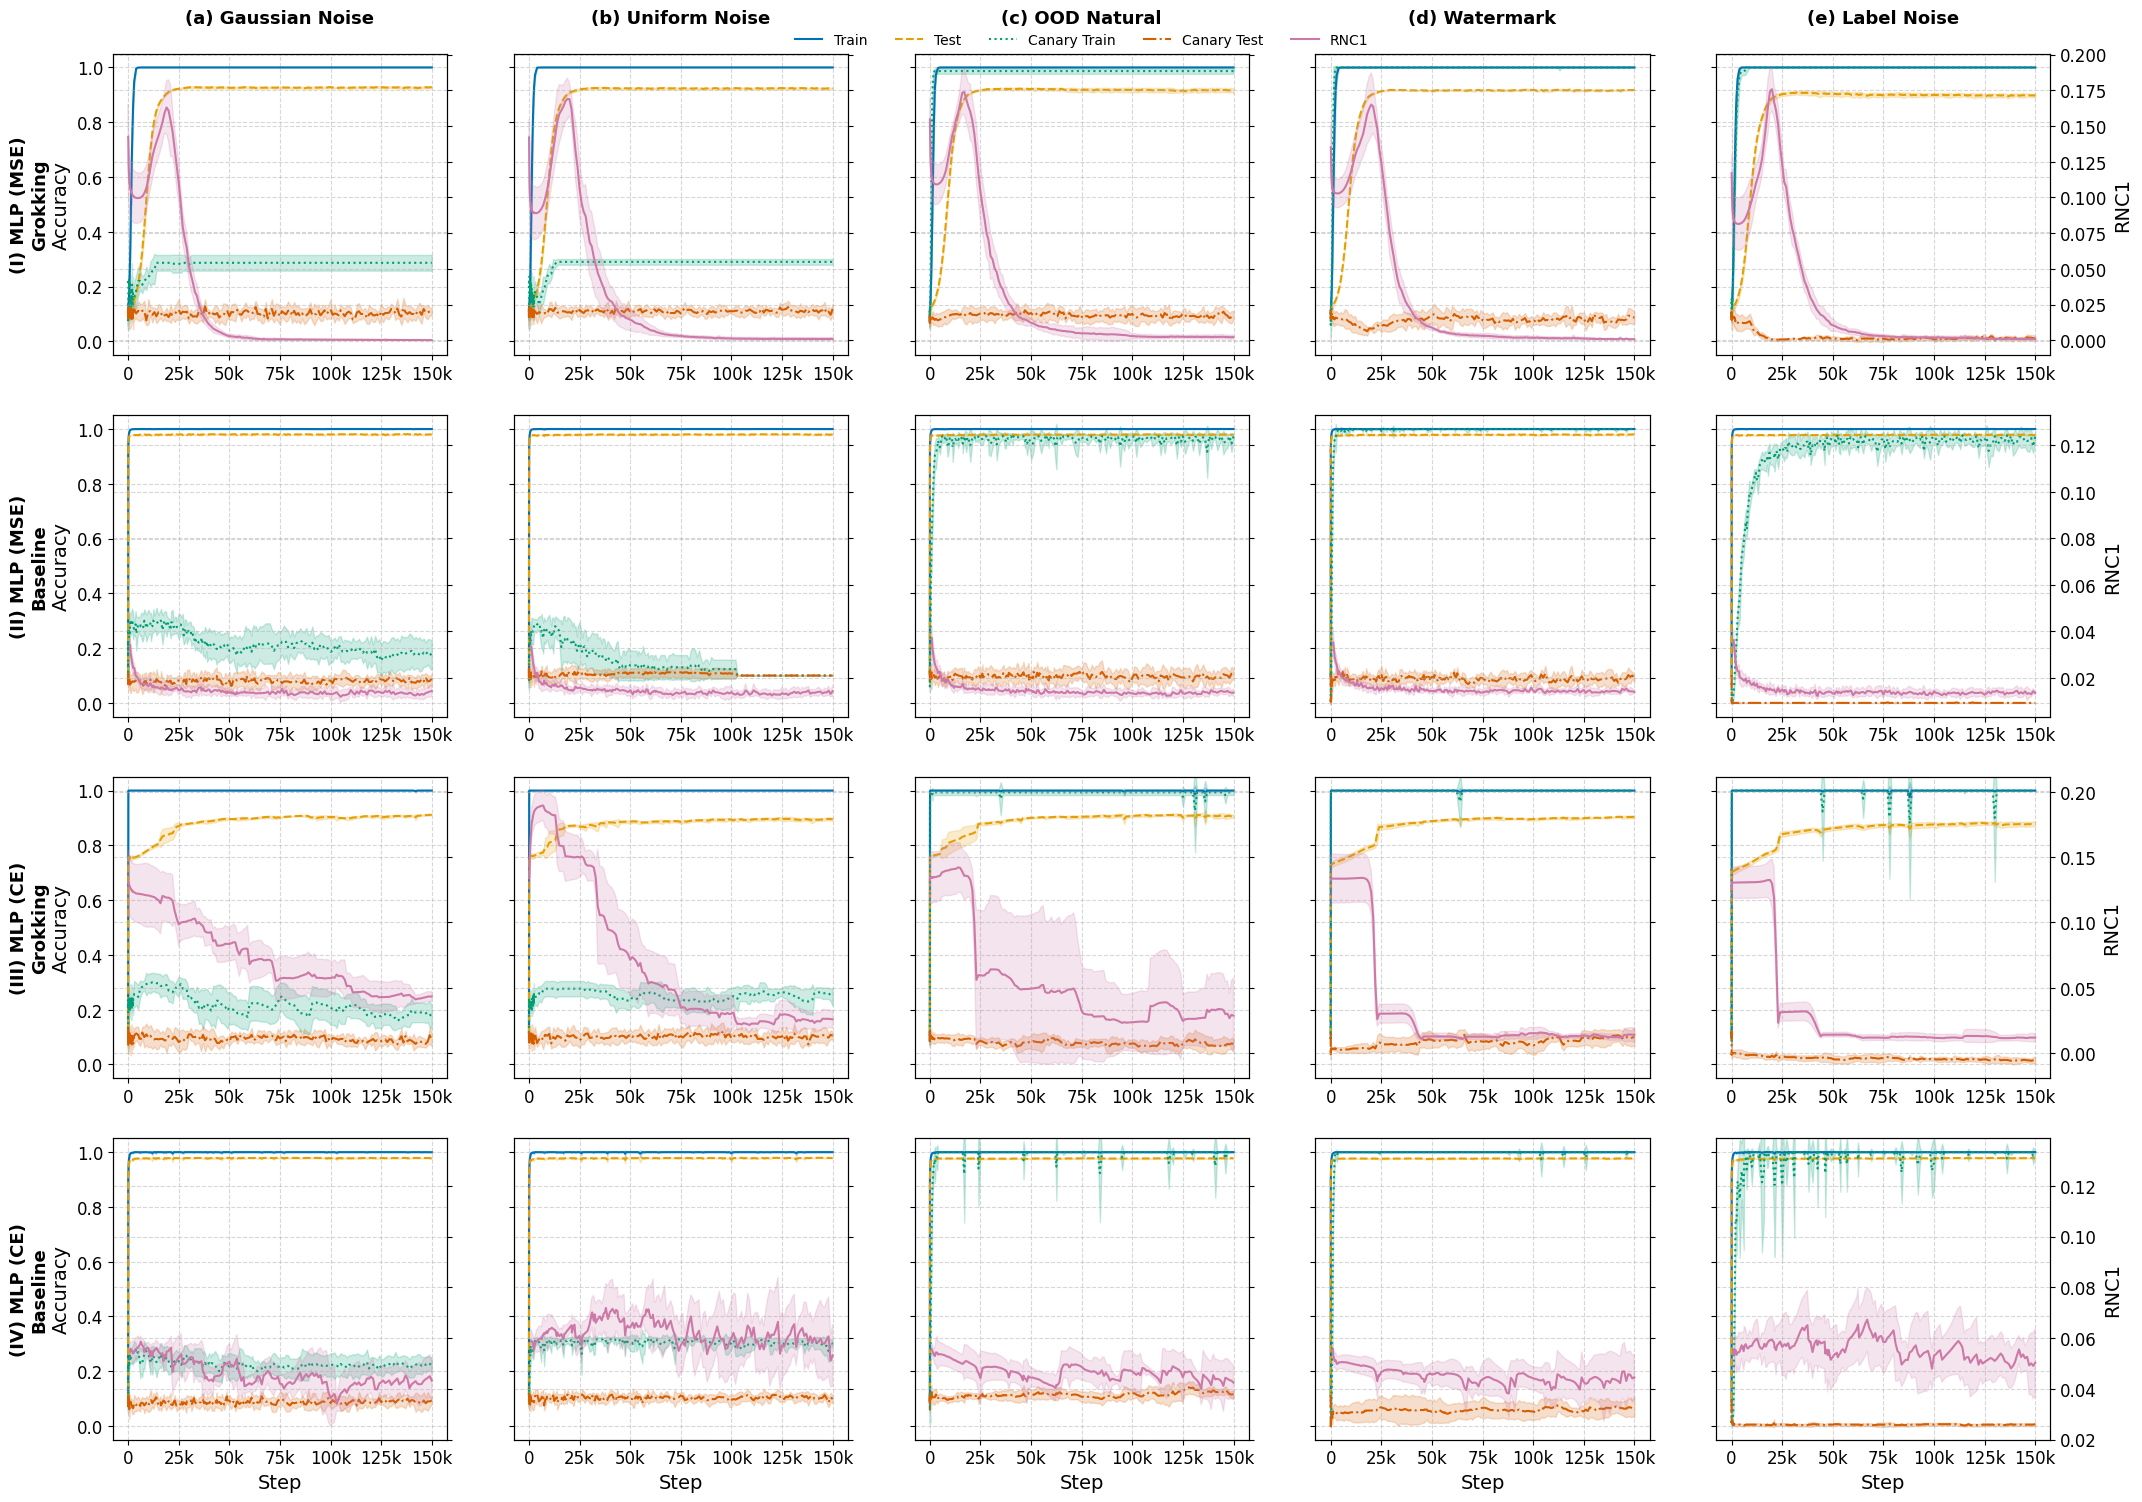

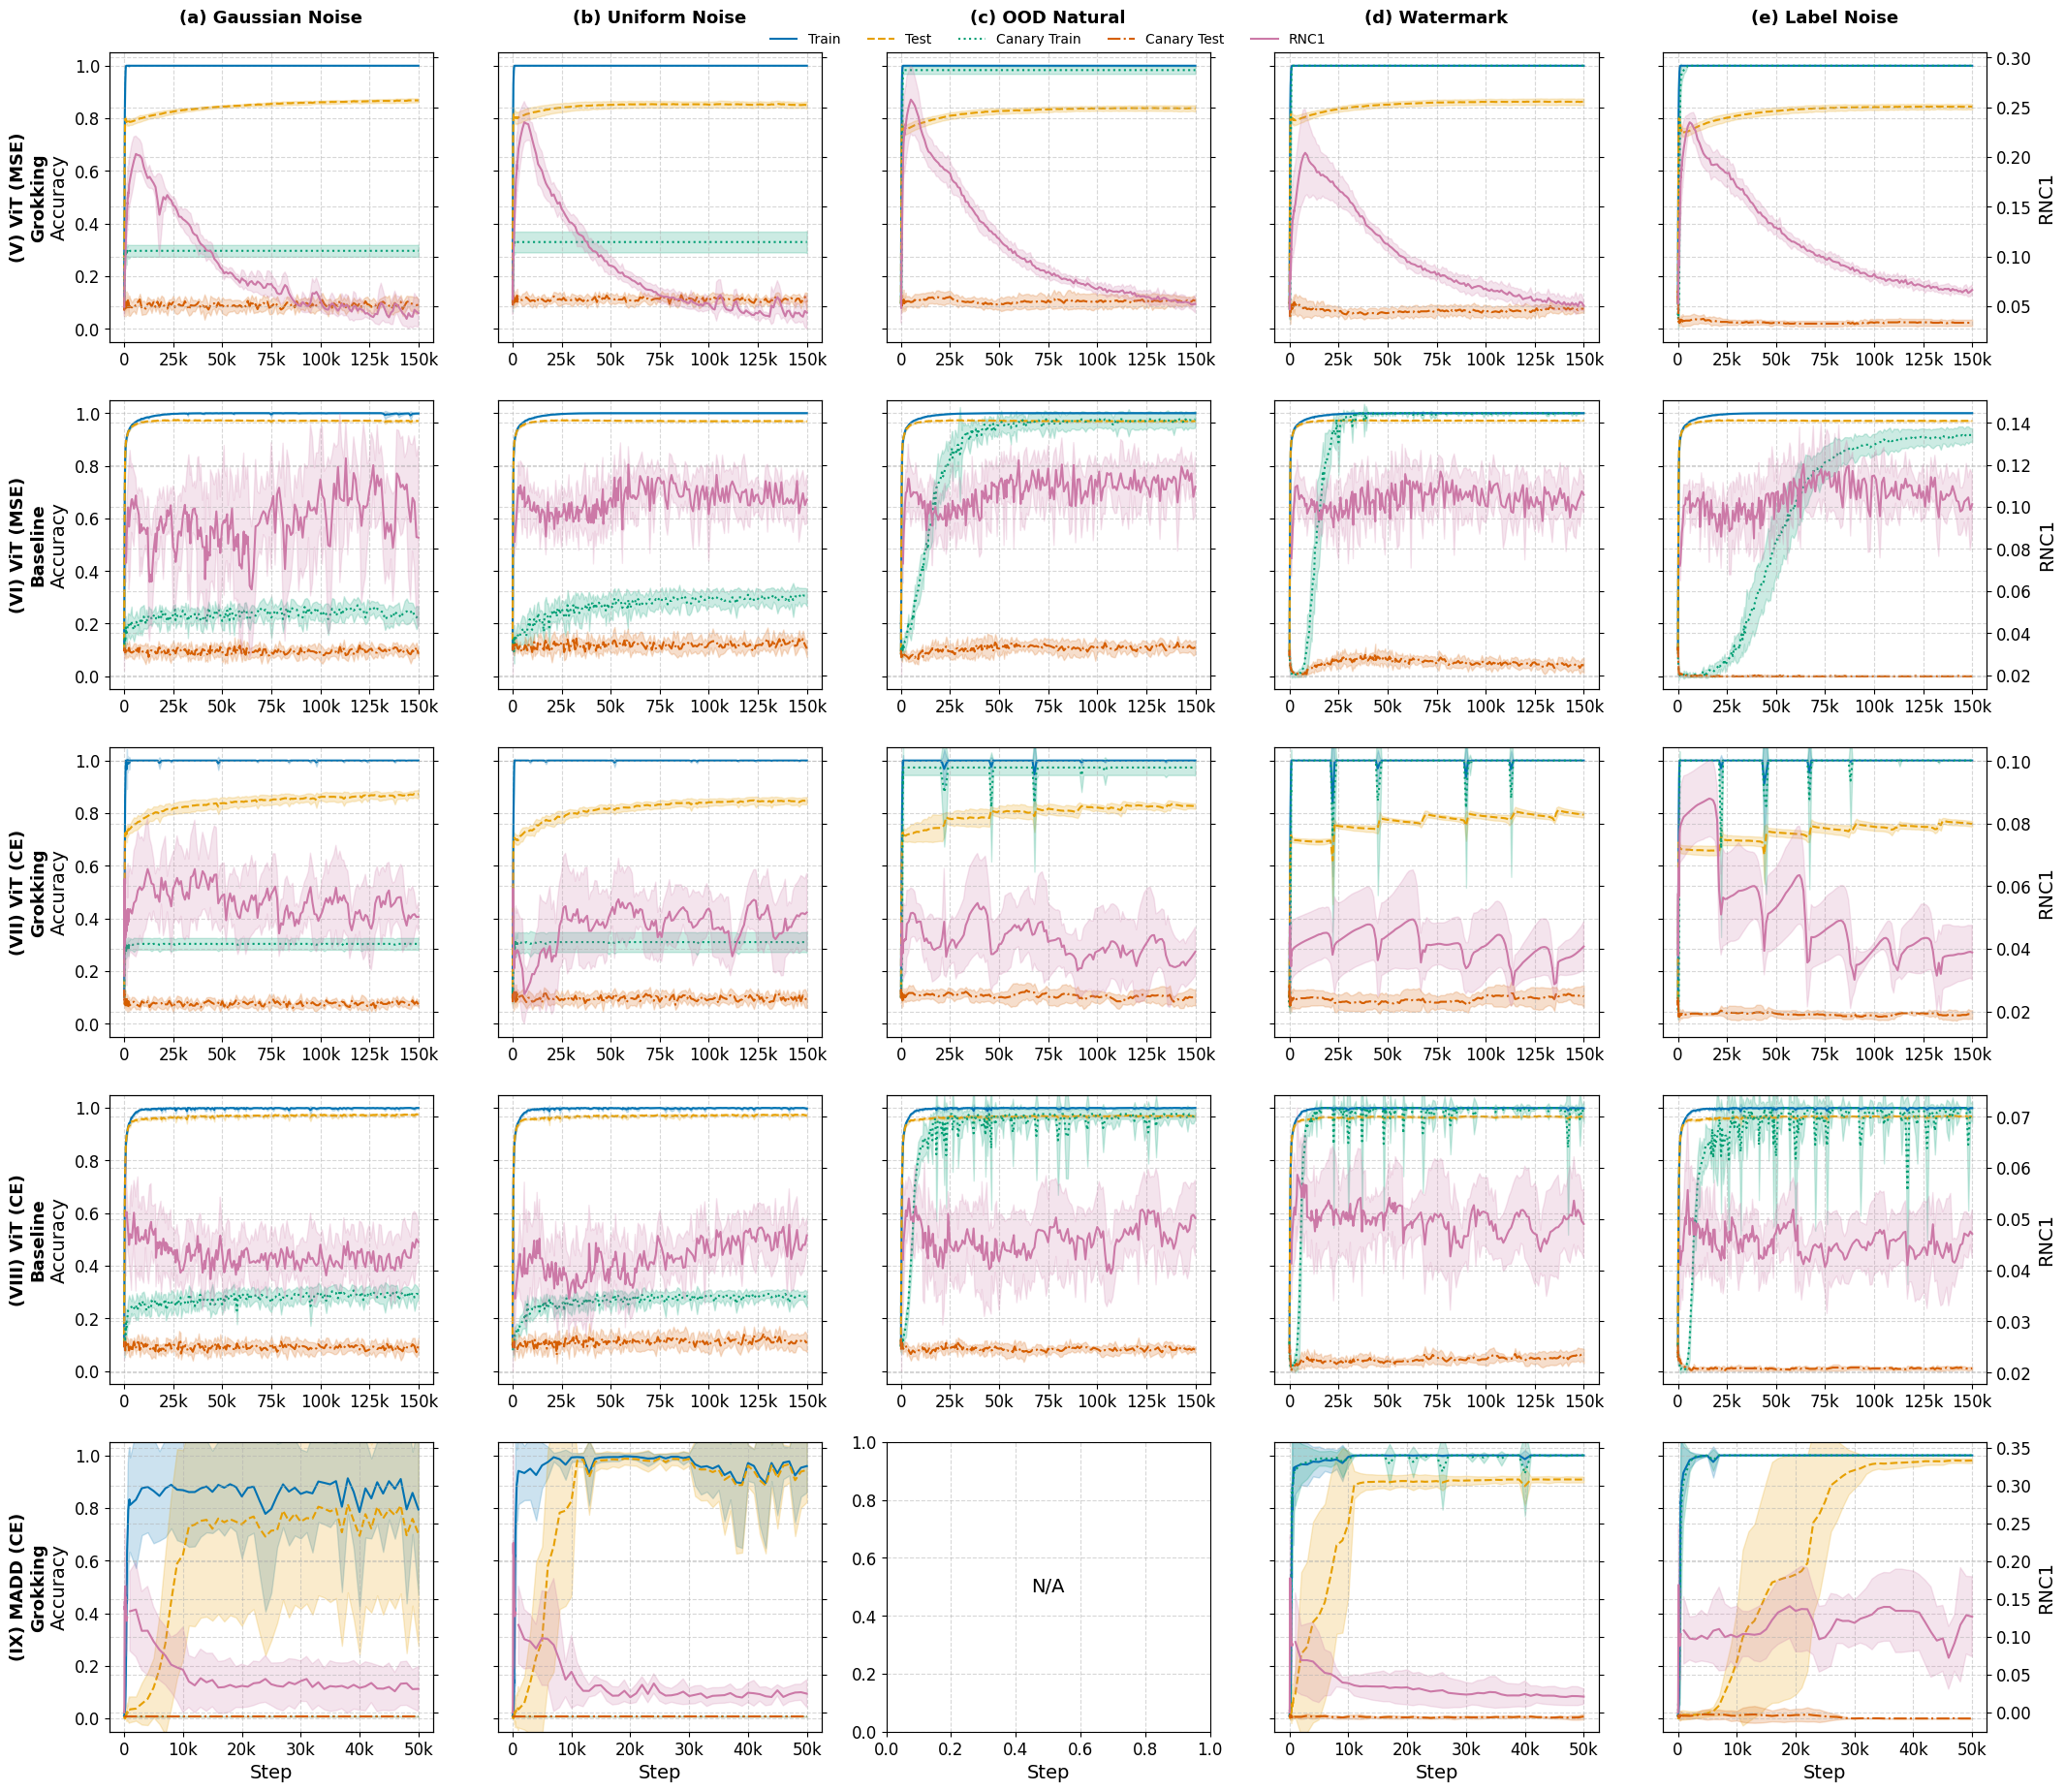

In [ ]:
CANARIES = {
    "GAUSSIAN_NOISE": "(a) Gaussian Noise",
    "UNIFORM_NOISE": "(b) Uniform Noise",
    "OOD_NATURAL": "(c) OOD Natural",
    "SQUARE_WATERMARK": "(d) Watermark",
    "LABEL_NOISE": "(e) Label Noise"
}
N_COLS = len(CANARIES)
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]

def plot_region(ax, df, metric, label, **kwargs):
    """Plot the across-seed mean and its ±1 std band for one metric.

    Line-only kwargs (e.g. ``linestyle``) are intentionally not forwarded to the
    band; otherwise the uncertainty ribbon would get a dashed border as well.
    """
    line = ax.plot(df["step"], df[f"{metric}_mean"], label=label, **kwargs)[0]
    ax.fill_between(
        df["step"],
        df[f"{metric}_mean"] - df[f"{metric}_std"],
        df[f"{metric}_mean"] + df[f"{metric}_std"],
        color=line.get_color(),
        alpha=0.2,
    )
    return line

for b in range(len(BATCHES)):
    batch = BATCHES[b]
    n_rows = len(batch)
    fig, axes = plt.subplots(n_rows, N_COLS, figsize=(5 * N_COLS, 4.5 * n_rows))

    for row in range(n_rows):
        title = SETUPS[batch[row]]
        ax = axes[row]

        ax[0].annotate(
            title,
            xy=(-0.25, 0.5),
            xycoords="axes fraction",
            fontsize=13,
            fontweight="bold",
            ha="center",
            va="center",
            rotation=90,
        )

        if row == n_rows - 1:
            for i in range(N_COLS):
                ax[i].set_xlabel("Step")

        reference_twin = None
        for col, (canary, column_name) in enumerate(CANARIES.items()):
            df = (
                metrics_df
                .filter((pl.col("title") == title) & (pl.col("run_name").str.contains(canary)))
                .group_by(["title", "step"])
                .agg([
                    cs.numeric().exclude("step").mean().name.suffix("_mean"),
                    cs.numeric().exclude("step").std().name.suffix("_std"),
                ])
                .sort(["title", "step"])
            )

            if (len(df) <= 0):
                ax[col].text(0.5, 0.5, "N/A", horizontalalignment="center", verticalalignment="center")
                continue

            plot_region(ax[col], df, "eval/train/accuracy", "Train", color=COLORS[0])
            plot_region(ax[col], df, "eval/test/accuracy", "Test", color=COLORS[1])
            plot_region(ax[col], df, "eval/train/canary_accuracy", "Canary Train", color=COLORS[2])
            plot_region(ax[col], df, "eval/test/canary_accuracy", "Canary Test", color=COLORS[3])
            if row == 0:
                ax[col].set_title(column_name, fontsize=13, fontweight="bold", pad=22)
            ax[col].set_ylim(-0.05, 1.05)
            ax[col].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
            ax[col].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
            ax[col].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))

            twin = ax[col].twinx()
            plot_region(twin, df, "eval/nc/rnc1/train", "RNC1", color=COLORS[4])
            if col == 0:
                ax[col].set_ylabel("Accuracy")
                reference_twin = twin
            else:
                ax[col].tick_params(labelleft=False)
                twin.sharey(reference_twin)
            if col != N_COLS - 1:
                twin.tick_params(labelright=False)
            else:
                twin.set_ylabel("RNC1")

    h1, l1 = axes[0, 2].get_legend_handles_labels()
    h2, l2 = twin.get_legend_handles_labels()
    axes[0, 2].legend(h1+h2, l1+l2, loc="lower center", bbox_to_anchor=(0.5, 0.98), ncol=len(l1+l2), frameon=False, fontsize=10)

    # plt.tight_layout()
    fig.savefig(PLOTS / f"canary_selection_v1_b{b}_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")

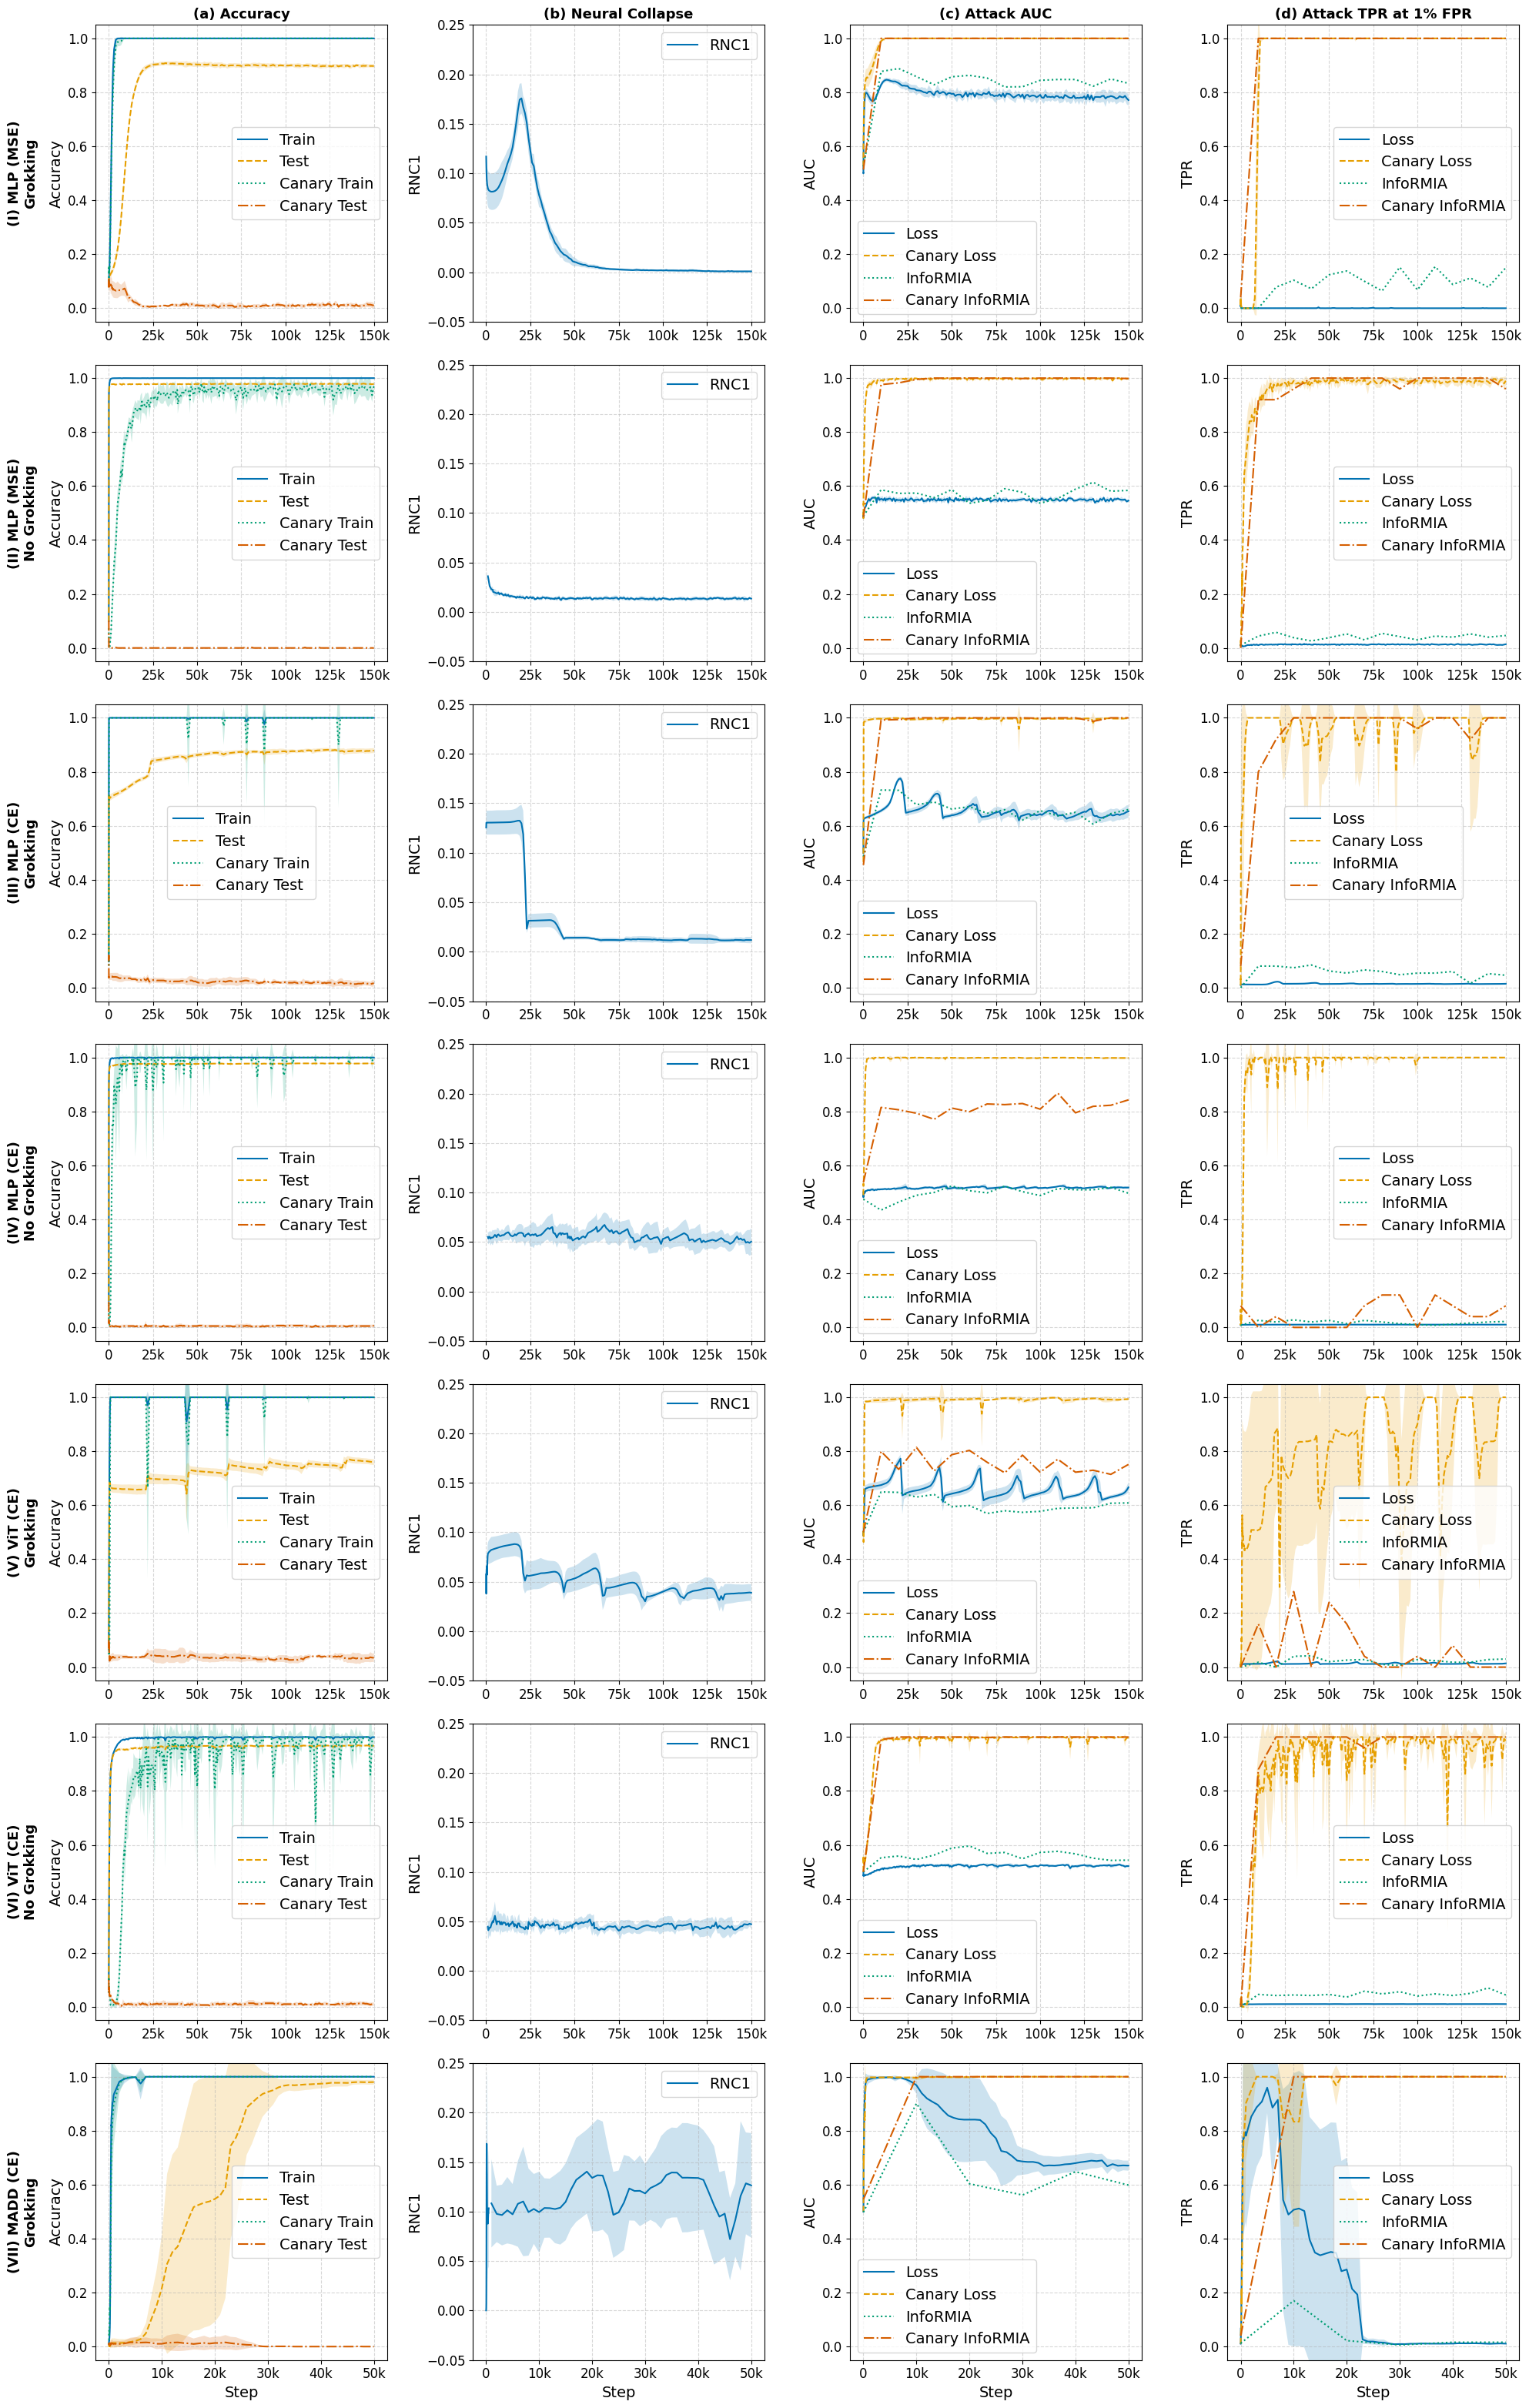

In [ ]:
N_COLS = 4
N_ROWS = len(SETUPS)
TITLES = list(SETUPS.values())

label_metrics_df = metrics_df.filter(pl.col("run_name").str.contains("LABEL_NOISE"))
label_info_rmia_df = info_rmia_df.filter(pl.col("run_name").str.contains("LABEL_NOISE"))

def plot_region(ax, df, metric, label, **kwargs):
    plot = ax.plot(df["step"], df[metric + "_mean"], label=label, **kwargs)
    ax.fill_between(
        df["step"],
        df[metric + "_mean"] - df[metric + "_std"],
        df[metric + "_mean"] + df[metric + "_std"],
        alpha=0.2,
        **kwargs
    )
    return plot

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row in range(N_ROWS):
    # TODO: Split by Attack, Batches

    title = TITLES[row]
    ax = axes[row]
    loss = "mse_loss" if "mse" in title else "ce_loss"

    df = (
        label_metrics_df
        .filter(pl.col("title") == title)
        .group_by(["title", "step"])
        .agg([
            cs.numeric().exclude("step").mean().name.suffix("_mean"),
            cs.numeric().exclude("step").std().name.suffix("_std"),
        ])
        .sort(["title", "step"])
    )
    info_df = (
        label_info_rmia_df
        .filter((pl.col("title") == title) & (pl.col("canary") == False))
        .sort(["step"])
    )
    canary_info_df = (
        label_info_rmia_df
        .filter((pl.col("title") == title) & (pl.col("canary") == True))
        .sort(["step"])
    )

    # Row Title
    ax[0].annotate(
        title,
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )

    # Y-Labels
    if row == N_ROWS - 1:
        for i in range(N_COLS):
            ax[i].set_xlabel("Step")

    # Plot
    if row == 0:
        ax[0].set_title("(a) Accuracy", fontsize=13, fontweight="bold")
    plot_region(ax[0], df, "eval/train/accuracy", "Train")
    plot_region(ax[0], df, "eval/test/accuracy", "Test")
    plot_region(ax[0], df, "eval/train/canary_accuracy", "Canary Train")
    plot_region(ax[0], df, "eval/test/canary_accuracy", "Canary Test")
    ax[0].set_ylabel("Accuracy")
    ax[0].set_ylim(-0.05, 1.05)
    ax[0].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[0].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[0].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[0].legend()

    if row == 0:
        ax[1].set_title("(b) Neural Collapse", fontsize=13, fontweight="bold")
    # styles = itertools.cycle(plt.rcParams['axes.prop_cycle'])
    # twinx = ax[1].twinx()
    plot_region(ax[1], df, "eval/nc/rnc1/train", "RNC1")
    # p1 = plot_region(ax[1], df, "eval/nc/nc1", "NC1", **next(styles))
    # p2 = plot_region(twinx, df, "eval/nc/rnc1/train", "RNC1", **next(styles))
    # ax[1].set_ylim(-0.05, 5.05)
    ax[1].set_ylim(-0.05, 0.25)
    # ax[1].set_yscale('log')
    ax[1].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[1].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[1].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[1].set_ylabel("RNC1")
    # ax[1].set_ylabel("NC1")
    # twinx.set_ylabel("RNC1")
    # plots = p1 + p2
    # labels = [l.get_label() for l in plots]
    # ax[1].legend(plots, labels)
    ax[1].legend()

    if row == 0:
        ax[2].set_title("(c) Attack AUC", fontsize=13, fontweight="bold")
    plot_region(ax[2], df, f"eval/attack/{loss}/auc", "Loss")
    plot_region(ax[2], df, f"eval/attack/canary_{loss}/auc", "Canary Loss")
    ax[2].plot(info_df["step"], info_df["auc"], label="InfoRMIA")
    # plot_region(ax[2], df, f"eval/attack/train_canary_vs_test/{loss}/auc", "Canary Loss")
    ax[2].plot(canary_info_df["step"], canary_info_df["auc"], label="Canary InfoRMIA")
    ax[2].set_ylabel("AUC")
    ax[2].set_ylim(-0.05, 1.05)
    ax[2].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[2].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[2].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[2].legend()

    if row == 0:
        ax[3].set_title("(d) Attack TPR at 1% FPR", fontsize=13, fontweight="bold")
    plot_region(ax[3], df, f"eval/attack/{loss}/tpr-at-fpr/1", "Loss")
    plot_region(ax[3], df, f"eval/attack/canary_{loss}/tpr-at-fpr/1", "Canary Loss")
    # plot_region(ax[3], df, f"eval/attack/train_canary_vs_test/{loss}/tpr-at-fpr/1", "Canary Loss")
    ax[3].plot(info_df["step"], info_df["tpr_at_0.01_fpr"], label="InfoRMIA")
    ax[3].plot(canary_info_df["step"], canary_info_df["tpr_at_0.01_fpr"], label="Canary InfoRMIA")
    ax[3].set_ylabel("TPR")
    ax[3].set_ylim(-0.05, 1.05)
    ax[3].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    ax[3].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    ax[3].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    ax[3].legend()

plt.tight_layout()
fig.savefig(PLOTS / f"canary_selection_v1_attacks_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")